# Effects of cell-type label noise on benchmarking results

In [1]:
import os
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
import scanpy as sc
import anndata as ad
import math
import colorcet as cc
from scipy.stats import wilcoxon, ttest_rel
from statsmodels.stats.multitest import multipletests
# import kendall_w as kw
from itertools import combinations
from sklearn.metrics import confusion_matrix

import matplotlib.font_manager as font_manager

font_manager.fontManager.addfont('/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')
prop = font_manager.FontProperties(fname='/ubc/cs/research/beaver/projects/yinian/fonts/arial.ttf')

plt.rcParams['font.family'] = 'sans-serif'
plt.rcParams['font.sans-serif'] = prop.get_name()

import sys
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scib/')
sys.path.insert(0, '/ubc/cs/research/beaver/projects/Single-cell-integration-metrics/scripts/project_utils/')
os.environ["R_HOME"] = "/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/R"

mm_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()
mm_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh.txt', header=None, index_col=0).index.to_numpy()

hg_s = pd.read_csv('../scib/scib/resources/s_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()
hg_g2m = pd.read_csv('../scib/scib/resources/g2m_genes_tirosh_hm.txt', header=None, index_col=0).index.to_numpy()

from analysis_helpers import *
import scib
from scib.metrics import *

/ubc/cs/research/beaver/projects/yinian/miniconda3/envs/scmetrics/lib/python3.10/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import get_distribution, DistributionNotFound


In [2]:
import rpy2.robjects as robjects
from rpy2.robjects import conversion, default_converter
from rpy2.robjects.pandas2ri import converter as pandas_converter

In [3]:
def compute_w_across_integrations(df, metric_cols=None, id_cols=('Dataset', 'Integration', 'LabelKey', 'percent')):
    if metric_cols is None:
        metric_cols = [c for c in df.columns if c not in id_cols]

    def compute_T(ranks_series):
        tie_counts = ranks_series.value_counts()
        tied = tie_counts[tie_counts > 1]
        return (tied**3 - tied).sum()

    results = []
    for metric in metric_cols:
        work = df[['Integration', 'percent', metric]].copy()

        work['Rank'] = work.groupby('percent')[metric].rank(ascending=False, method='average')

        pivot = work.pivot_table(index='Integration', columns='percent', values='Rank', aggfunc='first')

        n = pivot.shape[0]
        m = pivot.shape[1]

        R_i = pivot.sum(axis=1)
        sum_T = pivot.apply(compute_T, axis=0).sum()

        numerator   = 12 * (R_i**2).sum() - 3 * (m**2) * n * (n + 1)**2
        denominator = (m**2) * n * (n**2 - 1) - m * sum_T
        W = numerator / denominator if denominator != 0 else 0.0

        results.append({'Metric': metric, 'Kendall_W': W})

    return pd.DataFrame(results)

In [4]:
def make_fig(df, y, ylabel, invert=False, show_legend=False, legend_ncols=3):
    fig, ax = plt.subplots(1, 1, figsize=(.8, 1.7))

    sns.lineplot(
        data=df, 
        x='percent', 
        y=y, 
        hue='Integration', 
        marker='o', 
        markeredgewidth=0,
        markersize=2,
        linewidth=.5, 
        palette=INTEGRATION_COLOR_DICT, 
        ax=ax
    )
    if show_legend:
        sns.move_legend(
            ax, 
            "upper left", 
            bbox_to_anchor=(1, 1),
            ncols=legend_ncols,
            frameon=False,
            title="Integration",
            fontsize=5,
            title_fontsize=5,
            handlelength=1.0,
            columnspacing=0.8,
        )
    else:
        legend = ax.get_legend()
        if legend is not None:
            legend.remove()
    ax.patch.set_alpha(1.0)
    ax.tick_params(
        axis='both', which='major', width=.8,
        length=2, labelsize=5, pad=1
    )
    xticks = sorted(df['percent'].unique())
    ax.set_xticks(xticks)
    ax.set_xlabel('')
    ax.set_ylabel(ylabel, fontsize=5)
    if invert:
        ax.invert_yaxis()
    for spine in ax.spines.values():
        spine.set_linewidth(.45)
    ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
    for artist in ax.get_children():
        if hasattr(artist, 'get_rasterized') and artist.get_rasterized():
            print(artist, "is rasterized")
    fig.patch.set_alpha(0.0)
    ax.patch.set_alpha(0.0)
    return fig, ax

In [5]:
ordered_metrics = [
    'CCENT', 'HOMO', 'JACC', 'PURITY', 'NMIF', 'ARIF', 'BKNN', 'FKNN', 'MCC', 'F1', 'NNMAP', 'CNENT', 'OCS', 'KSIM', 'CLISI',  # Cluster-as-prediction and knn
    'BLOGREG', 'FLOGREG',
    'BAMI', 'BVM', 'BARI', 'AMI', 'NMI', 'VM', 'AWC', 'ARI', 'VI', 'FMI', # Cluster-label similarity
    'GC', 'CASW', 'CDBI', 'CCH',
    'COMP', 'PPTPC', 'PSTDB', # Joint bio&batch
    'SCGRAPH', 'SCGRAPHM', 'SCGRAPHP', 'MORANI',
    'BASW', 'EMBDIV', 'CPCR', 'CPROBE', 'CPROBELR', 'CPROBERF', 'BRAS', 'CILISI', 'KBET'
]

## Load data and plot trends
### Human lung

Data file: `../results/source_data/human_lung_label_noise.csv`

In [6]:
base = pd.concat([
    pd.read_csv('../results/final_benchmark/re_cpu_methods/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/re_gpu_methods/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/re_llm_methods/metrics/all-metrics.csv')
])
base = base[base['Dataset'] == 'human_lung']
base['Dataset'] = base['Dataset'] + '_label_0'
base['LabelKey'] = 'celltype_mutated'

In [7]:
df = pd.concat([
    pd.read_csv('../results/label_ablation/human_lung_cpu_v2/metrics/all-metrics.csv'),
    pd.read_csv('../results/label_ablation/human_lung_gpu_v2/metrics/all-metrics.csv'),
    pd.read_csv('../results/label_ablation/human_lung_llm_v2/metrics/all-metrics.csv'),
    base
])

In [8]:
df = df.pivot(index=['Dataset', 'Integration', 'LabelKey'], columns='Metric', values='Value').reset_index()

In [9]:
df['BIO'] = df[['BAMI', 'CASW', 'SCGRAPHM', 'ISOLISI']].mean(axis=1)
df['BATCH'] = (df['CPCR'] + df['BRAS'] + df['KBET']) / 3
df['OVERALL'] = df['BIO'] * .6 + df['BATCH'] * .4

In [10]:
df['Integration'] = df['Integration'].str[:-2]

In [11]:
df['Integration'] = df["Integration"].replace(NAME_MAP)

In [12]:
df['percent'] = df['Dataset'].str.split('_').str[-1].astype(int)

In [13]:
df.to_csv('../results/spreadsheets/human_lung_label_noise.csv', index=False)

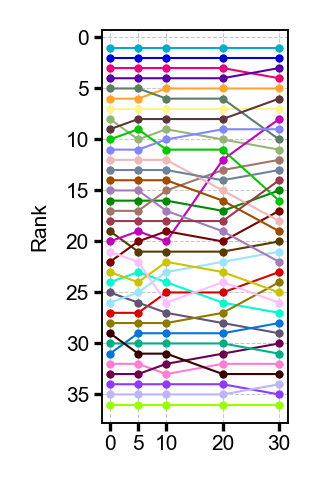

In [14]:
df['Rank'] = df.groupby(['percent'])['OVERALL'].rank(ascending=False, method='min')

with plt.rc_context({'figure.dpi': 300}):
    fig, ax = make_fig(df, 'Rank', 'Rank', invert=True)
#     plt.savefig('../publication_figures/human_lung_label_noise_rank.svg', bbox_inches='tight')
    plt.show()

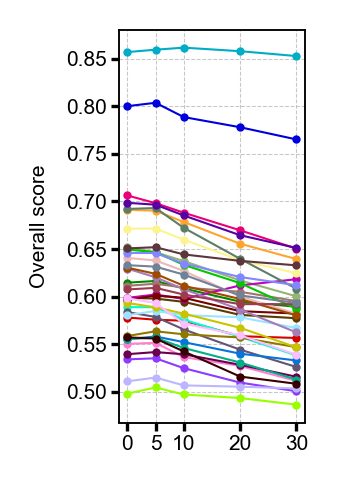

In [15]:
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = make_fig(df, 'OVERALL', 'Overall score', invert=False)
#     plt.savefig('../publication_figures/human_lung_label_noise_overall.svg', bbox_inches='tight')
    plt.show()

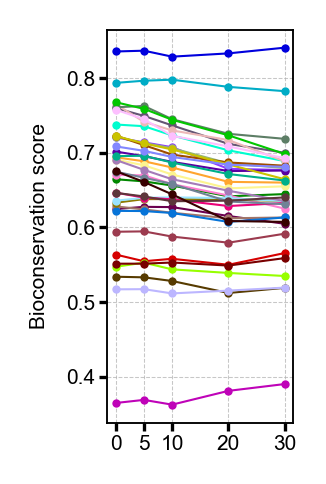

In [16]:
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = make_fig(df, 'BIO', 'Bioconservation score', invert=False)
#     plt.savefig('../publication_figures/human_lung_label_noise_bio.svg', bbox_inches='tight')
    plt.show()

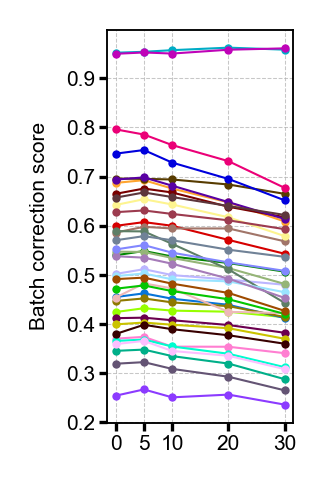

In [17]:
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = make_fig(df, 'BATCH', 'Batch correction score', invert=False)
#     plt.savefig('../publication_figures/human_lung_label_noise_batch.svg', bbox_inches='tight')
    plt.show()

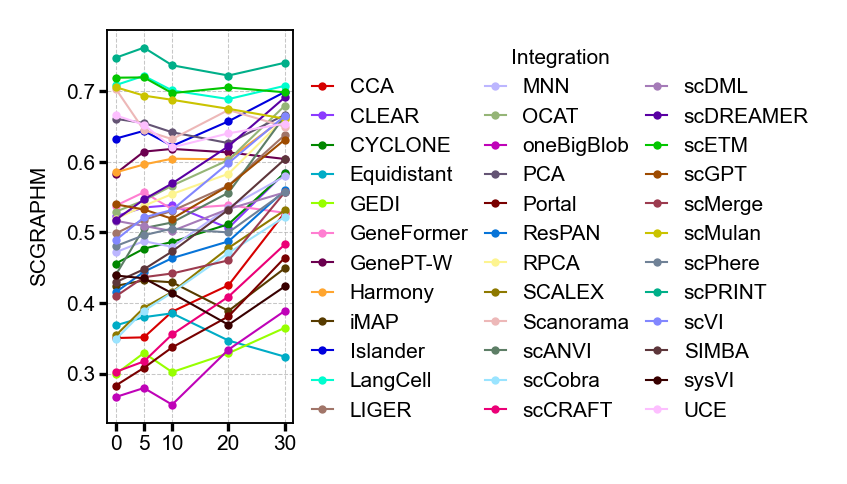

In [18]:
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = make_fig(df, 'SCGRAPHM', 'SCGRAPHM', invert=False, show_legend=True)
#     plt.savefig('../publication_figures/human_lung_label_noise_scgraph.svg', bbox_inches='tight')
    plt.show()

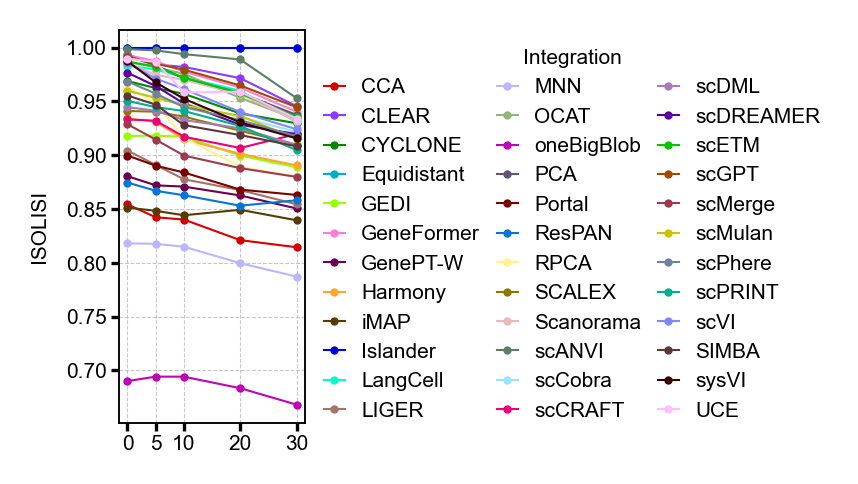

In [20]:
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = make_fig(df, 'ISOLISI', 'ISOLISI', invert=False, show_legend=True)
#     plt.savefig('../publication_figures/human_lung_label_noise_isolisi.svg', bbox_inches='tight')
    plt.show()

In [21]:
compute_w_across_integrations(df)

,Metric,Kendall_W
0,BAMI,0.976875
1,BRAS,0.990589
2,CASW,0.984947
3,CPCR,0.989622
4,ISOLISI,0.978808
5,KBET,0.986121
6,SCGRAPHM,0.942775
7,BIO,0.985400
8,BATCH,0.994481
9,OVERALL,0.977699


### Mouse cortex

Data file: `../results/source_data/mouse_cortex_label_noise.csv`

In [14]:
base = pd.concat([
    pd.read_csv('../results/final_benchmark/re_cpu_methods/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/re_gpu_methods/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/re_llm_methods/metrics/all-metrics.csv')
])
base = base[base['Dataset'] == 'mouse_cortex_sequencing_techs']
base['Dataset'] = 'mouse_cortex_seq_techs_label_0'
base['LabelKey'] = 'celltype_mutated'

In [15]:
df = pd.concat([
    pd.read_csv('../results/label_ablation/mouse_cortex_seq_techs_cpu_v2/metrics/all-metrics.csv'),
    pd.read_csv('../results/label_ablation/mouse_cortex_seq_techs_gpu_v2/metrics/all-metrics.csv'),
    base
])

In [16]:
df = df.pivot(index=['Dataset', 'Integration', 'LabelKey'], columns='Metric', values='Value').reset_index()

In [17]:
df['BIO'] = df[['BAMI', 'CASW', 'SCGRAPHM', 'ISOLISI']].mean(axis=1)
df['BATCH'] = (df['CPCR'] + df['BRAS'] + df['KBET']) / 3
df['OVERALL'] = df['BIO'] * .6 + df['BATCH'] * .4

In [18]:
df['Integration'] = df['Integration'].str[:-2]

In [19]:
df['Integration'] = df["Integration"].replace(NAME_MAP)

In [20]:
df['percent'] = df['Dataset'].str.split('_').str[-1].astype(int)

In [21]:
df.to_csv('../results/spreadsheets/mouse_cortex_label_noise.csv', index=False)

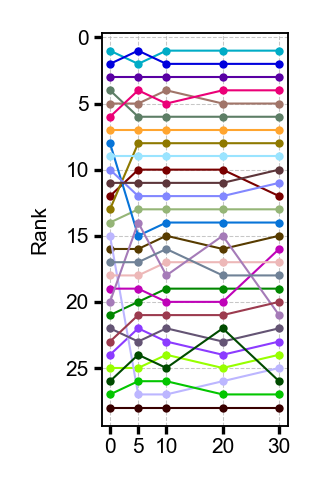

In [28]:
df['Rank'] = df.groupby(['percent'])['OVERALL'].rank(ascending=False, method='min')

with plt.rc_context({'figure.dpi': 300}):
    fig, ax = make_fig(df, 'Rank', 'Rank', invert=True)
#     plt.savefig('../publication_figures/mouse_cortex_label_noise_rank.svg', bbox_inches='tight')
    plt.show()

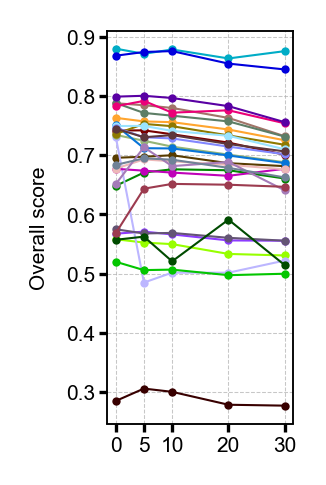

In [29]:
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = make_fig(df, 'OVERALL', 'Overall score', invert=False)
#     plt.savefig('../publication_figures/mouse_cortex_label_noise_overall.svg', bbox_inches='tight')
    plt.show()

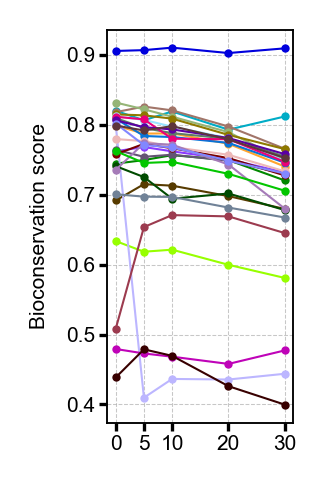

In [30]:
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = make_fig(df, 'BIO', 'Bioconservation score', invert=False)
#     plt.savefig('../publication_figures/mouse_cortex_label_noise_bio.svg', bbox_inches='tight')
    plt.show()

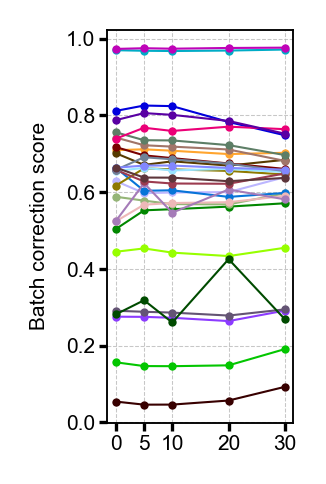

In [31]:
with plt.rc_context({'figure.dpi': 300}):
    fig, ax = make_fig(df, 'BATCH', 'Batch correction score', invert=False)
#     plt.savefig('../publication_figures/mouse_cortex_label_noise_batch.svg', bbox_inches='tight')
    plt.show()

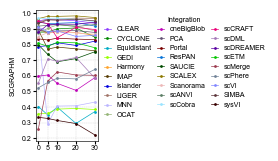

In [32]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'SCGRAPHM', 'SCGRAPHM', invert=False, show_legend=True)
#     plt.savefig('../publication_figures/mouse_cortex_label_noise_scgraph.svg', bbox_inches='tight')
    plt.show()

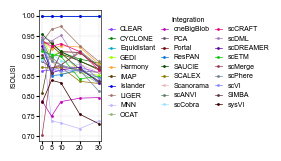

In [33]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'ISOLISI', 'ISOLISI', invert=False, show_legend=True)
#     plt.savefig('../publication_figures/mouse_cortex_label_noise_scgraph.svg', bbox_inches='tight')
    plt.show()

In [34]:
compute_w_across_integrations(df)

,Metric,Kendall_W
0,BAMI,0.952636
1,BRAS,0.987958
2,CASW,0.938522
3,CPCR,0.978275
4,ISOLISI,0.697739
5,KBET,0.969392
6,SCGRAPHM,0.942069
7,BIO,0.946886
8,BATCH,0.982573
9,OVERALL,0.972282


### 3_5_PBMC

Data file: `../results/source_data/3_5_pbmc_label_noise.csv`

In [22]:
base = pd.concat([
    pd.read_csv('../results/final_benchmark/re_cpu_methods_3_5_pbmc/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/re_gpu_methods_3_5_pbmc/metrics/all-metrics.csv'),
    pd.read_csv('../results/final_benchmark/re_llm_methods_3_5_pbmc/metrics/all-metrics.csv')
])
base = base[base['Dataset'] == '3_5_pbmc']
base['Dataset'] = base['Dataset'] + '_label_0'
base['LabelKey'] = 'celltype_mutated'

In [23]:
df = pd.concat([
    pd.read_csv('../results/label_ablation/3_5_pbmc_cpu_v2/metrics/all-metrics.csv'),
    pd.read_csv('../results/label_ablation/3_5_pbmc_gpu_v2/metrics/all-metrics.csv'),
    pd.read_csv('../results/label_ablation/3_5_pbmc_llm_v2/metrics/all-metrics.csv'),
    base
])

In [24]:
df = df.pivot(index=['Dataset', 'Integration', 'LabelKey'], columns='Metric', values='Value').reset_index()

In [25]:
df['BIO'] = df[['BAMI', 'CASW', 'SCGRAPHM']].mean(axis=1)
df['BATCH'] = (df['CPCR'] + df['BRAS'] + df['KBET']) / 3
df['OVERALL'] = df['BIO'] * .6 + df['BATCH'] * .4

In [26]:
df['Integration'] = df['Integration'].str[:-2]

In [27]:
df['Integration'] = df["Integration"].replace(NAME_MAP)

In [28]:
df['percent'] = df['Dataset'].str.split('_').str[-1].astype(int)

In [29]:
df = df[df.percent != 40]  # Exclude 40% label noise to be consistent with other data that only go up to 30%

In [30]:
df.to_csv('../results/spreadsheets/3_5_pbmc_label_noise.csv', index=False)

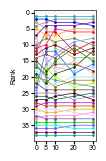

In [43]:
df['Rank'] = df.groupby(['percent'])['OVERALL'].rank(ascending=False, method='min')

with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'Rank', 'Rank', invert=True, show_legend=False)
#     plt.savefig('../publication_figures/3_5_pbmc_label_noise_rank.svg', bbox_inches='tight')
    plt.show()

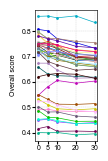

In [44]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'OVERALL', 'Overall score', invert=False)
#     plt.savefig('../publication_figures/3_5_pbmc_label_noise_overall.svg', bbox_inches='tight')
    plt.show()

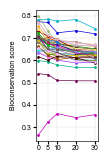

In [45]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'BIO', 'Bioconservation score', invert=False)
#     plt.savefig('../publication_figures/3_5_pbmc_label_noise_bio.svg', bbox_inches='tight')
    plt.show()

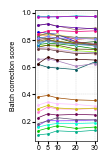

In [46]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'BATCH', 'Batch correction score', invert=False)
#     plt.savefig('../publication_figures/3_5_pbmc_label_noise_batch.svg', bbox_inches='tight')
    plt.show()

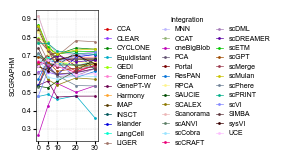

In [47]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'SCGRAPHM', 'SCGRAPHM', invert=False, show_legend=True)
#     plt.savefig('../publication_figures/3_5_pbmc_label_noise_scgraph.svg', bbox_inches='tight')
    plt.show()

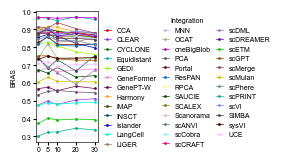

In [48]:
with plt.rc_context({'figure.dpi': 100}):
    fig, ax = make_fig(df, 'BRAS', 'BRAS', invert=False, show_legend=True)
    plt.show()

In [49]:
compute_w_across_integrations(df)

,Metric,Kendall_W
0,BAMI,0.889371
1,BRAS,0.967926
2,CASW,0.952765
3,CPCR,0.987520
4,KBET,0.991947
5,SCGRAPHM,0.735008
6,BIO,0.888530
7,BATCH,0.988253
8,OVERALL,0.965405
9,Rank,0.965405


## Analysis of mutated data characteristics

These plots produce the confusion matrix and overall mutation rate for each cell-type label.

In [50]:
runs = pd.read_csv('../results/spreadsheets/all_integrations.csv')

In [54]:
adata = sc.read('../data/mouse_cortex_seq_techs_label_10.h5ad')
adata

AnnData object with n_obs × n_vars = 13526 × 28692
    obs: 'nGene', 'nUMI', 'percent.mito', 'Cluster', 'CellType', 'Experiment', 'Method', 'celltype_mutated', 'was_mutated'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'seurat_v3_highly_variable', 'dispersions', 'dispersions_norm', 'ensembl_id', 'gene_name'
    uns: 'CellType_colors', 'Method_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'species', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts'
    obsp: 'connectivities', 'distances'

In [55]:
def plot_mutation_confusion(adata, true_col='celltype', mutated_col='celltype_mutated',
                              mutated_flag='was_mutated', batch_col='batch',
                              normalize='true', figsize=(3.3, 3.3)):
    """
    Plots confusion matrix of true vs. mutated label, restricted to mutated cells.
    normalize='true' -> rows sum to 1 (fraction of each true type that went where)
    normalize=None    -> raw counts
    """
    mutated = adata.obs[adata.obs[mutated_flag]]
    celltypes = adata.obs[true_col].cat.categories  # fixed, consistent ordering
    cm = confusion_matrix(
        mutated[true_col], mutated[mutated_col],
        labels=celltypes, normalize=normalize
    )
    cm_df = pd.DataFrame(cm, index=celltypes, columns=celltypes)
    plt.figure(figsize=figsize)
    ax = sns.heatmap(cm_df, annot=True, fmt='.2f' if normalize else 'd',
                      cmap='viridis', cbar=True, square=True,
                      xticklabels=True, yticklabels=True,
                      annot_kws={'fontsize': 5},
                      cbar_kws={'shrink': 0.7},
                    vmin=0, vmax=1)
    ax.set_xlabel('Mutated label', fontsize=5)
    ax.set_ylabel('True label', fontsize=5)
    ax.set_title('', fontsize=5)
    ax.tick_params(axis='both', labelsize=5)
    plt.setp(ax.get_xticklabels(), fontsize=5)
    plt.setp(ax.get_yticklabels(), fontsize=5)
    ax.tick_params(
        axis='both', which='major', width=.6,
        length=2, labelsize=5, pad=1
    )
    cbar = ax.collections[0].colorbar
    cbar.ax.tick_params(
        which='major', width=.45,
        length=2, labelsize=5, pad=1
    )
    plt.tight_layout()
    return ax

In [56]:
def plot_mutation_rate_by_celltype(adata, true_col='celltype', mutated_flag='was_mutated',
                                     figsize=(1.5, 1)):
    """
    Bar plot of the percentage of each true cell type that was mutated,
    i.e. (# mutated cells of type X) / (# total cells of type X).
    """
    celltypes = adata.obs[true_col].cat.categories

    total_counts = adata.obs[true_col].value_counts().reindex(celltypes)
    mutated_counts = adata.obs.loc[adata.obs[mutated_flag], true_col].value_counts().reindex(celltypes).fillna(0)

    pct_mutated = (mutated_counts / total_counts * 100).reindex(celltypes)

    fig, ax = plt.subplots(figsize=figsize)
    ax.bar(pct_mutated.index.astype(str), pct_mutated.values, color='steelblue')
    ax.set_ylabel('% mutated', fontsize=5)
    ax.set_xlabel('True cell type', fontsize=5)
#     ax.set_title('Percent of each cell type mutated', fontsize=5)
    ax.set_ylim(0, 100)
    for spine in ax.spines.values():
        spine.set_linewidth(.45)
    ax.tick_params(axis='both', which='major', width=.6, length=2, labelsize=5, pad=1)
    plt.setp(ax.get_xticklabels(), rotation=90, fontsize=5)
    plt.setp(ax.get_yticklabels(), fontsize=5)
    plt.tight_layout()
    return pct_mutated  # pandas Series, indexed by celltype


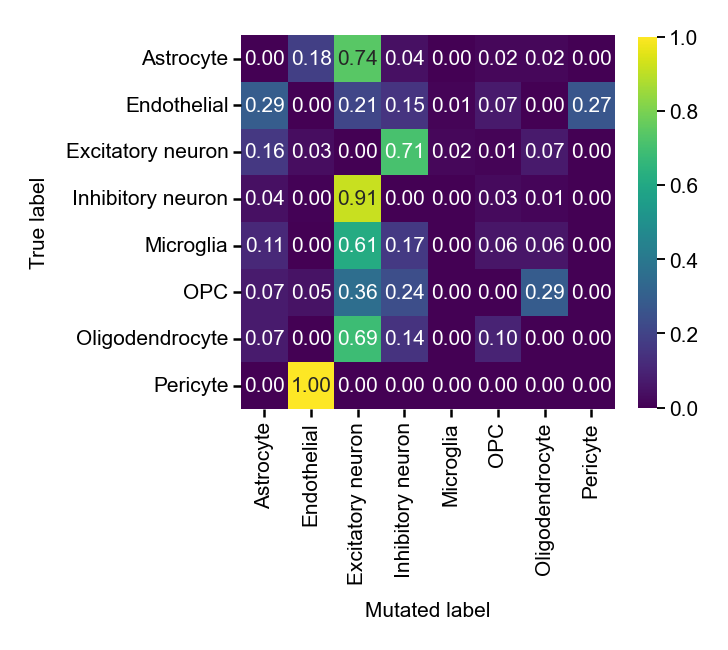

In [57]:
with plt.rc_context({'figure.dpi': 300}):
    ax = plot_mutation_confusion(adata, true_col='CellType', figsize=(2.8, 2.8))
#     plt.savefig('../publication_figures/mouse_cortex_label_noise_confusion.png', dpi=300, bbox_inches='tight')
    plt.show()

In [58]:
adata = sc.read('../data/human_lung_label_10.h5ad')
adata

AnnData object with n_obs × n_vars = 32472 × 15148
    obs: 'dataset', 'location', 'nGene', 'nUMI', 'patientGroup', 'percent.mito', 'protocol', 'sanger_type', 'size_factors', 'sampling_method', 'batch', 'cell_type', 'donor', 'celltype_mutated', 'was_mutated'
    var: 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'seurat_v3_highly_variable', 'dispersions', 'dispersions_norm'
    uns: 'cell_type_colors', 'donor_colors', 'hvg', 'log1p', 'neighbors', 'pca', 'species', 'umap'
    obsm: 'X_pca', 'X_umap'
    varm: 'PCs'
    layers: 'counts', 'orig_counts'
    obsp: 'connectivities', 'distances'

/tmp/ipykernel_404847/2006296337.py:25: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


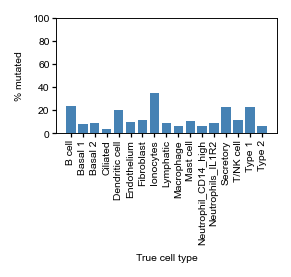

In [59]:
with plt.rc_context({'figure.dpi': 150}):
    pct_mutated = plot_mutation_rate_by_celltype(adata, true_col='cell_type', figsize=(1.9, 1))
#     plt.savefig('../publication_figures/human_lung_label_noise_pct_mutated.png', dpi=300, bbox_inches='tight')
    plt.show()

## Analyze all metrics

This is now including the metrics that we discarded after analyzing metrics.

In [60]:
def compute_w_across_integrations(df):
    rank_df = df.copy()
    rank_df['Rank'] = rank_df.groupby(['Metric', 'percent'])['Value'].rank(ascending=False, method='average')
    
    results = []
    for metric, group in rank_df.groupby('Metric'):
        pivot = group.pivot_table(index='Integration', columns='percent', values='Rank', aggfunc='first')

        n = pivot.shape[0]
        m = pivot.shape[1]

        R_i = pivot.sum(axis=1)

        def compute_T(ranks_series):
            tie_counts = ranks_series.value_counts()
            tied = tie_counts[tie_counts > 1]
            return (tied**3 - tied).sum()

        sum_T = pivot.apply(compute_T, axis=0).sum()

        # Kendall's W with tie correction
        numerator   = 12 * (R_i**2).sum() - 3 * (m**2) * n * (n + 1)**2
        denominator = (m**2) * n * (n**2 - 1) - m * sum_T

        W = numerator / denominator if denominator != 0 else 0.0

        results.append({'Metric': metric, 'Kendall_W': W})

    return pd.DataFrame(results)

### 3_5_PBMC

In [61]:
df1 = pd.read_csv('../results/label_ablation/3_5_pbmc_v1/metrics/all-metrics.csv')
df2 = pd.read_csv('../results/label_ablation/3_5_pbmc_v1_orig/metrics/all-metrics.csv')
df2['Dataset'] = df2['Dataset'] + '_label_0'
df2['Integration'] = df2['Integration']
df = pd.concat([df1, df2]).reset_index(drop=True)

In [62]:
df = df.drop_duplicates(
    subset=["Metric", "Dataset", "Integration", "LabelKey"],keep='last'  # Keep last means the most recent result will be stored.
)

target_metrics = ['MIX', 'KLDIV', 'KNNDIV']
mask = df['Metric'].isin(target_metrics)

# Multiply the 'Value' column by -1 only for rows matching the mask
df.loc[mask, 'Value'] = df.loc[mask, 'Value'] * -1

df['percent'] = df['Dataset'].str.split('_').str[-1].astype(int)

In [63]:
df = df[~df['Metric'].isin(['PROBEMIN'])]
df = df[~df['Value'].isna()]

In [64]:
df['Integration'] = df['Integration'].replace(NAME_MAP)

In [65]:
df = df[df['percent']!= 40] 

In [66]:
# Rename metrics
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH'
})

In [ ]:
df['Rank'] = df.groupby(['Metric', 'percent'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 8
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df['Integration'].unique()

with plt.rc_context({'figure.dpi': 300}):
    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height),
                             sharey=False, gridspec_kw={'wspace': 0.3})

    if num_rows == 1 and NUM_COLS == 1:
        axes = [axes]
    elif num_rows == 1 or NUM_COLS == 1:
        axes = axes.flatten()
    else:
        axes = axes.ravel()

    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df[df['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='percent',
            y='Rank',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Rank', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.invert_yaxis()
        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        ax.set_xlabel('')
        if i > len(metrics) - 9:
            ax.set_xlabel('Noise %', fontsize=5)
        ax.set_xticks([0, 5, 10, 20, 30])

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.03),
        ncols=13,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )

    plt.savefig('../publication_figures/3_5_pbmc_individual_metrics_rank.png', dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
df['Rank'] = df.groupby(['Metric', 'percent'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 8
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df['Integration'].unique()
color_map = palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

with plt.rc_context({'figure.dpi': 300}):
    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height),
                             sharey=False, gridspec_kw={'wspace': 0.3})

    if num_rows == 1 and NUM_COLS == 1:
        axes = [axes]
    elif num_rows == 1 or NUM_COLS == 1:
        axes = axes.flatten()
    else:
        axes = axes.ravel()

    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df[df['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='percent',
            y='Value',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Value', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        ax.set_xlabel('')
        if i > len(metrics) - 9:
            ax.set_xlabel('Noise %', fontsize=5)
        ax.set_xticks([0, 5, 10, 20, 30])
        if metric == 'CCH':
            ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 2))
            ax.yaxis.get_offset_text().set_fontsize(5)

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.03),
        ncols=13,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )

    plt.savefig('../publication_figures/3_5_pbmc_individual_metrics_overall.png', dpi=300, bbox_inches='tight')
    plt.show()

In [68]:
ws = compute_w_across_integrations(df).set_index('Metric').loc[ordered_metrics]

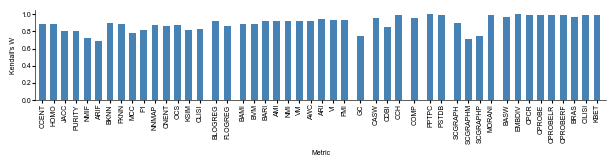

In [70]:
groups = [
    ["CCENT", "HOMO", "JACC", "PURITY", "NMIF", "ARIF", "BKNN", "FKNN", "MCC", "F1", "NNMAP", "CNENT", "OCS", "KSIM", "CLISI"],
    ["BLOGREG", "FLOGREG"],
    ["BAMI", "BVM", "BARI", "AMI", "NMI", "VM", "AWC", "ARI", "VI", "FMI"],
    ["GC"], ["CASW", "CDBI", "CCH"], ["COMP"],
    ["PPTPC", "PSTDB"], ["SCGRAPH", "SCGRAPHM", "SCGRAPHP", "MORANI"],
    ["BASW", "EMBDIV", "CPCR", "CPROBE", "CPROBELR", "CPROBERF", "BRAS", "CILISI", "KBET"],
]

bar_width = 0.25
within_group_gap = 1.0   # spacing between metrics within a group
between_group_gap = .4  # extra spacing added between groups

positions = []
labels = []
x = 0
for g_i, group in enumerate(groups):
    for metric in group:
        positions.append(x)
        labels.append(metric)
        x += within_group_gap
    x += between_group_gap
    
positions = np.array(positions)
values = [ws.loc[m, ws.columns[0]] for m in labels]
 
fig, ax = plt.subplots(figsize=(6.5, 2))
ax.bar(positions, values, width=0.6, color="steelblue")
ax.spines[['top', 'right']].set_visible(False)

ax.tick_params(
    axis='both', which='major', width=.8,
    length=2, labelsize=5, pad=1
)
ax.set_xlim(-0.6, 50)
for spine in ax.spines.values():
    spine.set_linewidth(.45)
ax.set_xticks(positions)
ax.set_xticklabels(labels, rotation=90)
ax.set_title("")
ax.set_xlabel("Metric", fontsize=5)
ax.set_ylabel("Kendall's W", fontsize=5)
ax.set_ylim(0, 1.05)
plt.tight_layout()
# plt.savefig("../publication_figures/3_5_pbmc_label_noise_W.png", dpi=300)
plt.show()

### Human lung

In [71]:
df1 = pd.read_csv('../results/label_ablation/human_lung_v1/metrics/all-metrics.csv')
df2 = pd.read_csv('../results/label_ablation/human_lung_v1_orig/metrics/all-metrics.csv')
df2['Dataset'] = df2['Dataset'] + '_label_0'
df2['Integration'] = df2['Integration']
df = pd.concat([df1, df2]).reset_index(drop=True)

In [72]:
df = df.drop_duplicates(
    subset=["Metric", "Dataset", "Integration", "LabelKey"],keep='last'  # Keep last means the most recent result will be stored.
)

target_metrics = ['MIX', 'KLDIV', 'KNNDIV']
mask = df['Metric'].isin(target_metrics)

# Multiply the 'Value' column by -1 only for rows matching the mask
df.loc[mask, 'Value'] = df.loc[mask, 'Value'] * -1

df['percent'] = df['Dataset'].str.split('_').str[-1].astype(int)

In [73]:
df = df[~df['Metric'].isin(['PROBEMIN'])]
df = df[~df['Value'].isna()]

In [74]:
df['Integration'] = df['Integration'].replace(NAME_MAP)

In [75]:
df = df[df['percent']!= 40] 

In [76]:
# Rename metrics
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH'
})

In [ ]:
df['Rank'] = df.groupby(['Metric', 'percent'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 8
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df['Integration'].unique()
color_map = palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

with plt.rc_context({'figure.dpi': 300}):
    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height),
                             sharey=False, gridspec_kw={'wspace': 0.3})

    if num_rows == 1 and NUM_COLS == 1:
        axes = [axes]
    elif num_rows == 1 or NUM_COLS == 1:
        axes = axes.flatten()
    else:
        axes = axes.ravel()

    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df[df['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='percent',
            y='Rank',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Rank', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.invert_yaxis()
        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        ax.set_xlabel('')
        if i > len(metrics) - 9:
            ax.set_xlabel('Noise %', fontsize=5)
        ax.set_xticks([0, 5, 10, 20, 30])

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.03),
        ncols=13,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )

    plt.savefig('../publication_figures/human_lung_individual_metrics_rank.png', dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
df['Rank'] = df.groupby(['Metric', 'percent'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 8
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df['Integration'].unique()
color_map = palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

with plt.rc_context({'figure.dpi': 300}):
    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height),
                             sharey=False, gridspec_kw={'wspace': 0.3})

    if num_rows == 1 and NUM_COLS == 1:
        axes = [axes]
    elif num_rows == 1 or NUM_COLS == 1:
        axes = axes.flatten()
    else:
        axes = axes.ravel()

    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df[df['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='percent',
            y='Value',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Value', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        ax.set_xlabel('')
        if i > len(metrics) - 9:
            ax.set_xlabel('Noise %', fontsize=5)
        ax.set_xticks([0, 5, 10, 20, 30])
        if metric == 'CCH':
            ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 2))
            ax.yaxis.get_offset_text().set_fontsize(5)

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.03),
        ncols=13,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )

    plt.savefig('../publication_figures/human_lung_individual_metrics_overall.png', dpi=300, bbox_inches='tight')
    plt.show()

In [77]:
ws = compute_w_across_integrations(df).set_index('Metric').loc[ordered_metrics]

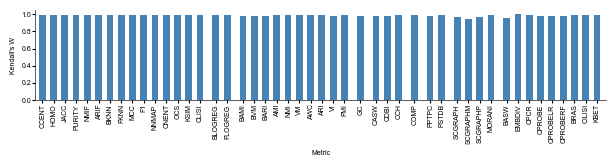

In [78]:
groups = [
    ["CCENT", "HOMO", "JACC", "PURITY", "NMIF", "ARIF", "BKNN", "FKNN", "MCC", "F1", "NNMAP", "CNENT", "OCS", "KSIM", "CLISI"],
    ["BLOGREG", "FLOGREG"],
    ["BAMI", "BVM", "BARI", "AMI", "NMI", "VM", "AWC", "ARI", "VI", "FMI"],
    ["GC"], ["CASW", "CDBI", "CCH"], ["COMP"],
    ["PPTPC", "PSTDB"], ["SCGRAPH", "SCGRAPHM", "SCGRAPHP", "MORANI"],
    ["BASW", "EMBDIV", "CPCR", "CPROBE", "CPROBELR", "CPROBERF", "BRAS", "CILISI", "KBET"],
]

bar_width = 0.25
within_group_gap = 1.0   # spacing between metrics within a group
between_group_gap = .4  # extra spacing added between groups

positions = []
labels = []
x = 0
for g_i, group in enumerate(groups):
    for metric in group:
        positions.append(x)
        labels.append(metric)
        x += within_group_gap
    x += between_group_gap
    
positions = np.array(positions)
values = [ws.loc[m, ws.columns[0]] for m in labels]
 
fig, ax = plt.subplots(figsize=(6.5, 2))
ax.bar(positions, values, width=0.6, color="steelblue")
ax.spines[['top', 'right']].set_visible(False)

ax.tick_params(
    axis='both', which='major', width=.8,
    length=2, labelsize=5, pad=1
)
ax.set_xlim(-0.6, 50)
for spine in ax.spines.values():
    spine.set_linewidth(.45)
ax.set_xticks(positions)
ax.set_xticklabels(labels, rotation=90)
ax.set_title("")
ax.set_xlabel("Metric", fontsize=5)
ax.set_ylabel("Kendall's W", fontsize=5)
ax.set_ylim(0, 1.05)
plt.tight_layout()
# plt.savefig("../publication_figures/human_lung_label_noise_W.png", dpi=300)
plt.show()

### Mouse cortex

In [79]:
df1 = pd.read_csv('../results/label_ablation/mouse_cortex_v1/metrics/all-metrics.csv')
df2 = pd.read_csv('../results/label_ablation/mouse_cortex_v1_orig/metrics/all-metrics.csv')
df2['Dataset'] = df2['Dataset'] + '_label_0'
df2['Integration'] = df2['Integration']
df = pd.concat([df1, df2]).reset_index(drop=True)

In [80]:
df = df.drop_duplicates(
    subset=["Metric", "Dataset", "Integration", "LabelKey"],keep='last'  # Keep last means the most recent result will be stored.
)

target_metrics = ['MIX', 'KLDIV', 'KNNDIV']
mask = df['Metric'].isin(target_metrics)

# Multiply the 'Value' column by -1 only for rows matching the mask
df.loc[mask, 'Value'] = df.loc[mask, 'Value'] * -1

df['percent'] = df['Dataset'].str.split('_').str[-1].astype(int)

In [81]:
df = df[~df['Metric'].isin(['PROBEMIN'])]
df = df[~df['Value'].isna()]

In [82]:
df['Integration'] = df['Integration'].replace(NAME_MAP)

In [83]:
# Rename metrics
df['Metric'] = df['Metric'].replace({
    'BNENTROPY': 'BNENT',
    'CNENTROPY': 'CNENT',
    'CCENTROPY': 'CCENT',
    'BCENTROPY': 'BCENT',
    'KNNDIV': 'EMBDIV',
    'CSMC': 'CSMS',
    'DBI': 'CDBI',
    'CH': 'CLUSTCH'
})

In [ ]:
df['Rank'] = df.groupby(['Metric', 'percent'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 8
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df['Integration'].unique()
color_map = palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

with plt.rc_context({'figure.dpi': 300}):
    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height),
                             sharey=False, gridspec_kw={'wspace': 0.3})

    if num_rows == 1 and NUM_COLS == 1:
        axes = [axes]
    elif num_rows == 1 or NUM_COLS == 1:
        axes = axes.flatten()
    else:
        axes = axes.ravel()

    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df[df['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='percent',
            y='Rank',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Rank', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.invert_yaxis()
        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        ax.set_xlabel('')
        if i > len(metrics) - 9:
            ax.set_xlabel('Noise %', fontsize=5)
        ax.set_xticks([0, 5, 10, 20, 30])

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.03),
        ncols=13,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )

    plt.savefig('../publication_figures/mouse_cortex_individual_metrics_rank.png', dpi=300, bbox_inches='tight')
    plt.show()

In [ ]:
df['Rank'] = df.groupby(['Metric', 'percent'])['Value'].rank(ascending=False, method='min')

NUM_COLS = 8
metrics = ordered_metrics
num_metrics = len(metrics)
num_rows = math.ceil(num_metrics / NUM_COLS)

fig_width = NUM_COLS * 1
fig_height = num_rows * 1.5

unique_integrations = df['Integration'].unique()
color_map = palette = sns.color_palette(cc.glasbey, n_colors=len(unique_integrations))

with plt.rc_context({'figure.dpi': 300}):
    fig, axes = plt.subplots(num_rows, NUM_COLS, figsize=(fig_width, fig_height),
                             sharey=False, gridspec_kw={'wspace': 0.3})

    if num_rows == 1 and NUM_COLS == 1:
        axes = [axes]
    elif num_rows == 1 or NUM_COLS == 1:
        axes = axes.flatten()
    else:
        axes = axes.ravel()

    for i, metric in enumerate(metrics):
        ax = axes[i]
        subset = df[df['Metric'] == metric]

        sns.lineplot(
            data=subset,
            x='percent',
            y='Value',
            hue='Integration',
            marker='o',
            markersize=1.5,
            markeredgewidth=0,
            linewidth=.45,
            palette=INTEGRATION_COLOR_DICT,
            ax=ax,
            legend=(i == 0),  # only build legend handles once
        )

        if i % NUM_COLS == 0:
            ax.set_ylabel('Value', fontsize=5)
        else:
            ax.set_ylabel('')

        ax.patch.set_alpha(1.0)
        ax.tick_params(
            axis='both', which='major', width=.8,
            length=2, labelsize=5, pad=1
        )
        for spine in ax.spines.values():
            spine.set_linewidth(.45)
        ax.grid(True, linestyle='--', alpha=0.7, linewidth=.25)
        
        ax.set_title(f'{metric}', fontsize=5, pad=1.6)
        ax.set_xlabel('')
        if i > len(metrics) - 9:
            ax.set_xlabel('Noise %', fontsize=5)
        ax.set_xticks([0, 5, 10, 20, 30])
        if metric == 'CCH':
            ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 2))
            ax.yaxis.get_offset_text().set_fontsize(5)

        if i == 0:
            handles, labels = ax.get_legend_handles_labels()
            ax.get_legend().remove()
        elif ax.get_legend() is not None:
            ax.get_legend().remove()

    for j in range(num_metrics, num_rows * NUM_COLS):
        fig.delaxes(axes[j])

    fig.legend(
        handles, labels,
        loc='lower center',
        bbox_to_anchor=(0.5, 0.03),
        ncols=13,
        frameon=False,
        title="Integration",
        fontsize=5,
        title_fontsize=5,
        handlelength=1.0,
        columnspacing=0.8,
    )

    plt.savefig('../publication_figures/mouse_cortex_individual_metrics_overall.png', dpi=300, bbox_inches='tight')
    plt.show()

In [85]:
ws = compute_w_across_integrations(df).set_index('Metric').loc[ordered_metrics]

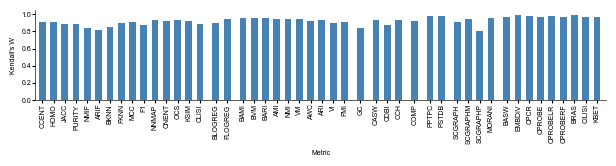

In [86]:
groups = [
    ["CCENT", "HOMO", "JACC", "PURITY", "NMIF", "ARIF", "BKNN", "FKNN", "MCC", "F1", "NNMAP", "CNENT", "OCS", "KSIM", "CLISI"],
    ["BLOGREG", "FLOGREG"],
    ["BAMI", "BVM", "BARI", "AMI", "NMI", "VM", "AWC", "ARI", "VI", "FMI"],
    ["GC"], ["CASW", "CDBI", "CCH"], ["COMP"],
    ["PPTPC", "PSTDB"], ["SCGRAPH", "SCGRAPHM", "SCGRAPHP", "MORANI"],
    ["BASW", "EMBDIV", "CPCR", "CPROBE", "CPROBELR", "CPROBERF", "BRAS", "CILISI", "KBET"],
]

bar_width = 0.25
within_group_gap = 1.0   # spacing between metrics within a group
between_group_gap = .4  # extra spacing added between groups

positions = []
labels = []
x = 0
for g_i, group in enumerate(groups):
    for metric in group:
        positions.append(x)
        labels.append(metric)
        x += within_group_gap
    x += between_group_gap
    
positions = np.array(positions)
values = [ws.loc[m, ws.columns[0]] for m in labels]
 
fig, ax = plt.subplots(figsize=(6.5, 2))
ax.bar(positions, values, width=0.6, color="steelblue")
ax.spines[['top', 'right']].set_visible(False)

ax.tick_params(
    axis='both', which='major', width=.8,
    length=2, labelsize=5, pad=1
)
ax.set_xlim(-0.6, 50)
for spine in ax.spines.values():
    spine.set_linewidth(.45)
ax.set_xticks(positions)
ax.set_xticklabels(labels, rotation=90)
ax.set_title("")
ax.set_xlabel("Metric", fontsize=5)
ax.set_ylabel("Kendall's W", fontsize=5)
ax.set_ylim(0, 1.05)
plt.tight_layout()
# plt.savefig("../publication_figures/mouse_cortex_label_noise_W.png", dpi=300)
plt.show()